# Top K 五日策略收益率榜单组合回测

本 Notebook 使用 WT8 CSV，对 `STRATEGY_CONFIG` 中配置的每一种第一层策略分别回测。第一层策略只提供各期货品种的历史策略权益；第二层在全局统一小时观察时点，根据该权益在过去五个有数据交易日的收益率进行横截面排名，入选 Top K 后直接买入对应期货合约，每个品种最多持有一手，组合最多同时持有 `TOP_K` 个品种。

## 计算口径

- 五日排名收益率：`第一层策略当前权益 ÷ 五个交易日之前的策略权益 - 1`。两端取各品种在对应交易日期、同一小时或此前最近一条有效记录；不足五个历史交易日的品种不参与排名。
- 排名来自所选第一层策略自己的历史权益；在统一排名时点，各品种只使用不晚于该时点的最新权益数据。超过 `MAX_SCORE_AGE_HOURS` 的陈旧评分不参与排名。组合的实际持仓盈亏由期货价格变化计算，不直接复制第一层策略自身的盈亏。
- 同一品种、同一时间戳的重复行按最后一行作为该时点快照。每个自然小时数据桶全局只排名一次，采用该小时桶内最后一个实际观测时间作为统一排名时点；委托在该品种排名时点之后的下一条行情记录成交。
- 一手盈亏为`价格变化 × 合约乘数`。杠杆通过保证金占用体现，不会再乘一次。
- 手续费使用配置的单边费率；滑点、实际换月交易及主连换月价差暂未完整建模。

## 如何添加第一层策略

在第 1 个代码单元的 `STRATEGY_CONFIG` 中新增一项，并将 `folder` 指向包含相同格式 WT8 CSV 的数据目录。名称和颜色都从此配置读取，汇总图、净值图、持仓图会自动按配置生成，不需要再分别修改绘图单元格。

默认 `UNIVERSE_POLICY = "common"`，所有策略使用共同品种池，便于横向比较；设置为 `"per_strategy"` 时，各策略使用各自可用数据中的品种，覆盖范围可能不同。新增策略若历史范围较短，`END_AT = None` 会按所有配置策略的共同末时点截断回测区间，这是为了保持比较区间一致。

该回测用于研究“基于第一层策略近期历史收益选品”的期货轮动组合，不代表实际成交结果。


In [1]:
from collections import Counter, defaultdict
from dataclasses import dataclass
from datetime import datetime, timedelta
from html import escape
from itertools import groupby
from heapq import merge
from pathlib import Path
from statistics import median
from typing import NamedTuple
import csv
import math
import re
import statistics

# ============================================================
# 回测参数：后续新增第一层策略时，只需要在 STRATEGY_CONFIG 增加一项。
# folder 必须指向包含 WT8 信号明细 CSV 的数据目录。
# ============================================================
STRATEGY_CONFIG = {
    "long_hold": {
        "folder": "小时Buy_And_Hold",
        "name": "Long & Hold（五日收益率榜）",
        "color": "#187a63",
    },
    "sar_long": {
        "folder": "小时SAR多头",
        "name": "小时 SAR 多头",
        "color": "#3568c8",
    },
    "macd_long": {
        "folder": "小时MACD多头",
        "name": "小时 MACD 多头",
        "color": "#d17c20",
    },
    # 新增示例（复制后修改即可；默认不启用，避免读取不存在的目录）：
    # "rsi_long": {
    #     "folder": "小时RSI多头",
    #     "name": "小时 RSI 多头",
    #     "color": "#9467bd",
    # },
}
STRATEGY_DIRS = {key: config["folder"] for key, config in STRATEGY_CONFIG.items()}
STRATEGY_NAMES = {key: config["name"] for key, config in STRATEGY_CONFIG.items()}
STRATEGY_COLORS = {key: config["color"] for key, config in STRATEGY_CONFIG.items()}

INITIAL_CAPITAL = 500_000.0
TOP_K = 10
LOOKBACK_TRADING_DAYS = 5
MAX_SCORE_AGE_HOURS = 24.0  # 超过该时长未更新的评分不参与排名；允许通常夜盘/午间休市
START_AT = "2024-01-02 09:30:00"
END_AT = None  # None 表示取所有已配置策略共同覆盖到的最后时点
ONE_WAY_FEE_RATE = 0.0  # 单边手续费率；例如 0.0001 表示名义成交额的 1 bp
UNIVERSE_POLICY = "common"  # "common" = 共同品种池；"per_strategy" = 各策略使用自身可用品种

if not STRATEGY_CONFIG:
    raise ValueError("STRATEGY_CONFIG 至少需要配置一个第一层策略。")
if UNIVERSE_POLICY not in {"common", "per_strategy"}:
    raise ValueError('UNIVERSE_POLICY 只能是 "common" 或 "per_strategy"。')
if TOP_K < 1 or LOOKBACK_TRADING_DAYS < 1:
    raise ValueError("TOP_K 和 LOOKBACK_TRADING_DAYS 必须是正整数。")
if INITIAL_CAPITAL <= 0 or ONE_WAY_FEE_RATE < 0:
    raise ValueError("初始资金必须大于 0，手续费率不能小于 0。")
if MAX_SCORE_AGE_HOURS <= 0:
    raise ValueError("MAX_SCORE_AGE_HOURS 必须大于 0。")

# 明确区分：第一层策略输入在 data/；第二层组合回测产物在 backtest_output/。
# 支持从项目根目录、notebooks/ 子目录或其下级目录启动 Notebook。
_CWD = Path.cwd().resolve()
_CANDIDATE_ROOTS = (_CWD, *_CWD.parents)
BASE_DIR = next(
    (p for p in _CANDIDATE_ROOTS if (p / "data").is_dir() and (p / "notebooks").is_dir()),
    None,
)
if BASE_DIR is None:
    BASE_DIR = next((p for p in _CANDIDATE_ROOTS if (p / "data").is_dir()), None)
if BASE_DIR is None:
    raise FileNotFoundError(
        f"从当前工作目录 {_CWD} 向上找不到项目 data/ 目录；请确认在 Futures_Ranking 项目内运行。"
    )

DATA_DIR = BASE_DIR / "data"
OUTPUT_DIR = BASE_DIR / "backtest_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Notebook 当前工作目录：", _CWD)
print("项目根目录 BASE_DIR：", BASE_DIR)
print("第一层策略输入目录 DATA_DIR：", DATA_DIR)
print("第二层组合输出目录 OUTPUT_DIR：", OUTPUT_DIR)
print("各策略输入 CSV 检查：")
for _strategy_id, _config in STRATEGY_CONFIG.items():
    _source_dir = DATA_DIR / _config["folder"]
    _csv_count = len(list(_source_dir.glob("*.csv"))) if _source_dir.is_dir() else 0
    print(f"  {_strategy_id}: {_source_dir}（CSV 文件数：{_csv_count}）")
    if not _source_dir.is_dir() or _csv_count == 0:
        raise FileNotFoundError(
            f"第一层策略 {_strategy_id} 没有可读取的 CSV：{_source_dir}。请检查 STRATEGY_CONFIG['folder']。"
        )

print("已配置第一层策略：", ", ".join(STRATEGY_NAMES.values()))
print("排名口径：统一小时观察时点前", LOOKBACK_TRADING_DAYS, "个有数据交易日的第一层策略权益收益率")
print("评分最大允许陈旧时长：", MAX_SCORE_AGE_HOURS, "小时")
print("回测区间：", START_AT, "至", (END_AT or "所有已配置策略共同末时点"))
print("品种池模式：", UNIVERSE_POLICY)
print("初始资金：", f"{INITIAL_CAPITAL:,.0f}", "元；每品种 1 手；组合最多", TOP_K, "个品种")


Notebook 当前工作目录： D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\notebooks
项目根目录 BASE_DIR： D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking
第一层策略输入目录 DATA_DIR： D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\data
第二层组合输出目录 OUTPUT_DIR： D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\backtest_output
各策略输入 CSV 检查：
  long_hold: D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\data\小时Buy_And_Hold（CSV 文件数：83）
  sar_long: D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\data\小时SAR多头（CSV 文件数：83）
  macd_long: D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\data\小时MACD多头（CSV 文件数：83）
已配置第一层策略： Long & Hold（五日收益率榜）, 小时 SAR 多头, 小时 MACD 多头
排名口径：统一小时观察时点前 5 个有数据交易日的第一层策略权益收益率
评分最大允许陈旧时长： 24.0 小时
回测区间： 2024-01-02 09:30:00 至 所有已配置策略共同末时点
品种池模式： common
初始资金： 500,000 元；每品种 1 手；组合最多 10 个品种


## 1. 读取和检查 WT8 明细

以下按 CSV 的固定列读取：时间、合约、信号、价格、平仓/开仓手数、成交额、手续费、可用资金、权益。读取时同时根据 BK/SP 还原 WT8 每个单品种策略自己的持仓状态，用于估算保证金率。新增第一层策略时，请确保新目录中的 CSV 列结构一致，并在第 1 个代码单元的 `STRATEGY_CONFIG` 中注册。


In [2]:
class Bar(NamedTuple):
    timestamp: datetime
    contract: str
    signal: str
    price: float | None
    turnover: float | None
    trade_qty: float | None
    equity: float
    available: float | None
    position: int
    fee: float | None


def parse_number(value):
    text = str(value or "").replace("\ufeff", "").strip().replace(",", "")
    if not text or text in {"---", "--", "-"}:
        return None
    try:
        return float(text)
    except ValueError:
        return None


def parse_timestamp(value):
    text = str(value or "").replace("\ufeff", "").strip()
    for fmt in ("%Y/%m/%d %H:%M:%S", "%Y-%m-%d %H:%M:%S", "%Y/%m/%d %H:%M", "%Y-%m-%d %H:%M"):
        try:
            return datetime.strptime(text, fmt)
        except ValueError:
            pass
    return None


def instrument_name(path):
    name = re.sub(r"_小时.*?_信号明细$", "", path.stem)
    name = re.sub(r"_信号明细$", "", name)
    return re.sub(r"\s+", "", name)


def read_bars(path):
    raw_rows = None
    last_error = None
    for encoding in ("gb18030", "gbk", "utf-8-sig"):
        try:
            with path.open("r", encoding=encoding, errors="strict", newline="") as handle:
                reader = csv.reader(handle)
                next(reader, None)
                raw_rows = list(reader)
            break
        except UnicodeDecodeError as exc:
            last_error = exc
    if raw_rows is None:
        raise UnicodeError(f"无法解码 {path.name}: {last_error}")

    bars = []
    position = 0
    for raw in raw_rows:
        if len(raw) < 15:
            continue
        timestamp = parse_timestamp(raw[1])
        equity = parse_number(raw[14])
        if timestamp is None or equity is None:
            continue  # 汇总行或无效行
        signal = str(raw[3] or "").strip()
        if signal == "BK":
            position = 1
            trade_qty = parse_number(raw[9])
        elif signal in {"SP", "SK", "BP"}:
            trade_qty = parse_number(raw[8])
            if signal == "SP":
                position = 0
            else:
                position = 0
        else:
            trade_qty = None
        bars.append(Bar(
            timestamp=timestamp,
            contract=str(raw[2] or "").strip(),
            signal=signal,
            price=parse_number(raw[7]),
            turnover=parse_number(raw[10]),
            trade_qty=trade_qty,
            equity=equity,
            available=parse_number(raw[13]),
            position=position,
            fee=parse_number(raw[11]),
        ))
    bars.sort(key=lambda bar: bar.timestamp)
    return bars


def format_dt(value):
    return value.strftime("%Y-%m-%d %H:%M:%S") if value else ""


def load_strategy_rows(strategy_id):
    directory = DATA_DIR / STRATEGY_DIRS[strategy_id]
    result = {}
    for path in sorted(directory.glob("*.csv")):
        name = instrument_name(path)
        bars = read_bars(path)
        if bars:
            result[name] = bars
    return result


print("明细读取函数已准备好。")

明细读取函数已准备好。


## 2. 从 WT8 交易和资金字段估算合约乘数、保证金率

乘数用所有已配置策略 CSV 的 BK/SP 实际成交金额交叉核对。保证金率不是从网上套一个统一值，而是从每个品种持仓期间的 `权益 - 可用资金` 反推；同一时点若不同策略都有持仓，取这些观察的中位数。回测时只取不晚于当前时点的最近比率，不用未来保证金记录。


In [3]:
MULTIPLIER_SAMPLES = defaultdict(list)
RAW_MARGIN_SAMPLES = defaultdict(list)
DATA_AUDIT = {}
INSTRUMENTS_BY_STRATEGY = {}
TIMESTAMPS_BY_STRATEGY_INSTRUMENT = {}
DATA_FEES = Counter()

for strategy_id, folder in STRATEGY_DIRS.items():
    paths = sorted((DATA_DIR / folder).glob("*.csv"))
    row_count = 0
    signals = Counter()
    first_time = None
    last_time = None
    populated = set()
    strategy_timestamps = {}
    for path in paths:
        name = instrument_name(path)
        bars = read_bars(path)
        if bars:
            populated.add(name)
            strategy_timestamps[name] = [bar.timestamp for bar in bars]
        for bar in bars:
            row_count += 1
            first_time = bar.timestamp if first_time is None else min(first_time, bar.timestamp)
            last_time = bar.timestamp if last_time is None else max(last_time, bar.timestamp)
            if bar.signal:
                signals[bar.signal] += 1
            if bar.fee is not None:
                DATA_FEES[strategy_id] += bar.fee
            if bar.signal in {"BK", "SP"} and bar.price and bar.turnover and bar.trade_qty:
                MULTIPLIER_SAMPLES[name].append(bar.turnover / (bar.price * bar.trade_qty))
            if bar.position and bar.price and bar.equity is not None and bar.available is not None:
                margin_amount = bar.equity - bar.available
                if margin_amount > 0:
                    RAW_MARGIN_SAMPLES[name].append((bar.timestamp, margin_amount, bar.price))
    INSTRUMENTS_BY_STRATEGY[strategy_id] = populated
    TIMESTAMPS_BY_STRATEGY_INSTRUMENT[strategy_id] = strategy_timestamps
    DATA_AUDIT[strategy_id] = {
        "strategy": STRATEGY_NAMES[strategy_id],
        "files": len(paths),
        "with_rows": len(populated),
        "rows": row_count,
        "first": first_time,
        "last": last_time,
        "BK": signals["BK"],
        "SP": signals["SP"],
    }


CONTRACT_MULTIPLIER = {}
MULTIPLIER_DISPERSION = {}
for name, samples in MULTIPLIER_SAMPLES.items():
    center = median(samples)
    nearest_integer = round(center)
    multiplier = float(nearest_integer) if nearest_integer > 0 and abs(center - nearest_integer) <= max(0.01, center * 0.005) else center
    CONTRACT_MULTIPLIER[name] = multiplier
    MULTIPLIER_DISPERSION[name] = max(abs(value - multiplier) / multiplier for value in samples)


MARGIN_HISTORY = {}
MARGIN_STATS = {}
for name, samples in RAW_MARGIN_SAMPLES.items():
    multiplier = CONTRACT_MULTIPLIER.get(name)
    if not multiplier:
        continue
    dated_rates = []
    for timestamp, margin_amount, price in samples:
        notional = price * multiplier
        rate = margin_amount / notional if notional else None
        if rate is not None and 0.001 <= rate <= 0.50:
            dated_rates.append((timestamp, rate))
    dated_rates.sort(key=lambda item: item[0])
    timeline = []
    for timestamp, grouped in groupby(dated_rates, key=lambda item: item[0]):
        same_time_rates = [item[1] for item in grouped]
        timeline.append((timestamp, median(same_time_rates)))
    if timeline:
        MARGIN_HISTORY[name] = timeline
        all_rates = [item[1] for item in timeline]
        MARGIN_STATS[name] = {
            "samples": len(dated_rates),
            "observations": len(timeline),
            "median": median(all_rates),
            "min": min(all_rates),
            "max": max(all_rates),
        }
MARGIN_TIMES = {name: [item[0] for item in history] for name, history in MARGIN_HISTORY.items()}


missing_strategy_data = [key for key, audit in DATA_AUDIT.items() if audit["last"] is None]
if missing_strategy_data:
    missing_labels = ", ".join(STRATEGY_NAMES[key] for key in missing_strategy_data)
    raise RuntimeError(f"以下策略目录没有可读取的有效 CSV 数据：{missing_labels}。请检查 STRATEGY_CONFIG 的 folder。")

ALL_SEEN_INSTRUMENTS = set.union(*(set(names) for names in INSTRUMENTS_BY_STRATEGY.values()))
if UNIVERSE_POLICY == "common":
    ELIGIBLE_UNIVERSE = set.intersection(*(set(names) for names in INSTRUMENTS_BY_STRATEGY.values()))
else:
    ELIGIBLE_UNIVERSE = set.union(*(set(names) for names in INSTRUMENTS_BY_STRATEGY.values()))
ELIGIBLE_UNIVERSE &= set(CONTRACT_MULTIPLIER)
ELIGIBLE_UNIVERSE &= set(MARGIN_HISTORY)
EXCLUDED_INSTRUMENTS = sorted(ALL_SEEN_INSTRUMENTS - ELIGIBLE_UNIVERSE)
if not ELIGIBLE_UNIVERSE:
    raise RuntimeError("没有同时具备价格、合约乘数和保证金率的可回测品种。")

START_DT = parse_timestamp(START_AT)
latest_per_strategy = [DATA_AUDIT[key]["last"] for key in STRATEGY_DIRS]
COMMON_LAST_DT = min(latest_per_strategy)
_requested_end_dt = parse_timestamp(END_AT) if END_AT else COMMON_LAST_DT
if START_DT is None or _requested_end_dt is None:
    raise ValueError("请设置有效的回测起止时间。")
END_DT = min(_requested_end_dt, COMMON_LAST_DT)
if START_DT >= END_DT:
    raise ValueError("请设置有效回测区间，且起始时点必须早于结束时点。")
if END_AT and _requested_end_dt > COMMON_LAST_DT:
    print(f"注意：结束时间超过已配置策略的共同数据覆盖范围，已截断至 {format_dt(COMMON_LAST_DT)}。")

# 构建全局一致的小时排名时钟：对每个自然小时桶，选择所有已配置策略、可回测品种
# 在该小时内最后一个真实数据时间戳作为当次排名时点。这样同一小时不会因不同品种的
# 09:00/09:15 等时间戳差异重复排名，并且统一时点之前的数据才可参与排名。
_all_eligible_timestamps = set()
for _strategy_timestamps in TIMESTAMPS_BY_STRATEGY_INSTRUMENT.values():
    for _instrument, _timestamps in _strategy_timestamps.items():
        if _instrument in ELIGIBLE_UNIVERSE:
            _all_eligible_timestamps.update(_timestamps)

_hour_bucket_last_timestamp = {}
for _timestamp in _all_eligible_timestamps:
    if not (START_DT < _timestamp <= END_DT):
        continue
    _hour_bucket = _timestamp.replace(minute=0, second=0, microsecond=0)
    if _hour_bucket not in _hour_bucket_last_timestamp or _timestamp > _hour_bucket_last_timestamp[_hour_bucket]:
        _hour_bucket_last_timestamp[_hour_bucket] = _timestamp
GLOBAL_HOURLY_CLOCK = sorted(_hour_bucket_last_timestamp.values())
GLOBAL_HOURLY_CLOCK_SET = set(GLOBAL_HOURLY_CLOCK)
if not GLOBAL_HOURLY_CLOCK:
    raise RuntimeError("回测区间内没有可用的小时排名观察时点，请检查时间范围和 CSV 时间戳。")

def margin_rate_at(name, timestamp):
    history = MARGIN_HISTORY.get(name, [])
    times = MARGIN_TIMES.get(name, [])
    idx = bisect_right(times, timestamp) - 1
    return history[idx][1] if idx >= 0 else None


from bisect import bisect_right

def margin_table_rows():
    rows = []
    for name in sorted(ELIGIBLE_UNIVERSE):
        stats = MARGIN_STATS[name]
        start_rate = margin_rate_at(name, START_DT)
        rows.append({
            "品种": name,
            "合约乘数": CONTRACT_MULTIPLIER[name],
            "乘数反推成交笔数": len(MULTIPLIER_SAMPLES[name]),
            "乘数最大偏差": MULTIPLIER_DISPERSION[name],
            "起始保证金率": start_rate,
            "起始隐含杠杆": 1 / start_rate if start_rate else None,
            "期间保证金率中位数": stats["median"],
            "期间保证金率最低": stats["min"],
            "期间保证金率最高": stats["max"],
            "WT8保证金观察数": stats["samples"],
        })
    return rows


def show_html(html):
    try:
        from IPython.display import HTML, display
        display(HTML(html))
    except ImportError:
        print("当前 Python 环境没有 IPython，Notebook 在 Jupyter 中会显示 HTML 图表和表格。")


def show_table(rows, columns, percent_columns=(), number_columns=()):
    head = "".join(f"<th>{escape(col)}</th>" for col in columns)
    body = []
    for row in rows:
        cells = []
        for col in columns:
            value = row.get(col)
            if value is None:
                rendered = "—"
            elif col in percent_columns:
                rendered = f"{value * 100:,.2f}%"
            elif col in number_columns:
                rendered = f"{value:,.2f}"
            elif isinstance(value, datetime):
                rendered = format_dt(value)
            elif isinstance(value, float):
                rendered = f"{value:,.4f}"
            else:
                rendered = str(value)
            cells.append(f"<td>{escape(rendered)}</td>")
        body.append("<tr>" + "".join(cells) + "</tr>")
    html = "<table style='border-collapse:collapse;font-size:13px'>"
    html += "<thead><tr>" + head + "</tr></thead><tbody>" + "".join(body) + "</tbody></table>"
    show_html(html)


audit_rows = []
for key in STRATEGY_DIRS:
    audit = DATA_AUDIT[key]
    audit_rows.append({
        "策略": audit["strategy"],
        "CSV文件": audit["files"],
        "有行情的品种": audit["with_rows"],
        "有效行数": audit["rows"],
        "BK开仓信号": audit["BK"],
        "SP平仓信号": audit["SP"],
        "开始": audit["first"],
        "结束": audit["last"],
        "CSV手续费合计": DATA_FEES[key],
    })
show_table(audit_rows, ["策略", "CSV文件", "有行情的品种", "有效行数", "BK开仓信号", "SP平仓信号", "开始", "结束", "CSV手续费合计"])
if UNIVERSE_POLICY == "common":
    print(f"所有已配置策略共同且具备回测参数的品种：{len(ELIGIBLE_UNIVERSE)} 个。")
else:
    print(f"所有已配置策略可用品种的并集（且具备回测参数）：{len(ELIGIBLE_UNIVERSE)} 个；每个策略只回测自身实际有数据的品种。")
print(f"未纳入品种：{', '.join(EXCLUDED_INSTRUMENTS) or '无'}（缺少有效行情、合约乘数或保证金率）。")
print(f"有效区间：{format_dt(START_DT)} 至 {format_dt(END_DT)}。全局小时排名时点：{len(GLOBAL_HOURLY_CLOCK)} 个；每个时点仅使用不晚于该时点、且评分年龄不超过 {MAX_SCORE_AGE_HOURS:g} 小时的 WT8 记录。")
print("CSV 原始手续费合计：", ", ".join(f"{STRATEGY_NAMES[key]}={value:,.2f}" for key, value in DATA_FEES.items()))
print(f"组合回测使用统一单边手续费率 ONE_WAY_FEE_RATE={ONE_WAY_FEE_RATE:g}；CSV 原始手续费字段不直接计入组合盈亏。")


策略,CSV文件,有行情的品种,有效行数,BK开仓信号,SP平仓信号,开始,结束,CSV手续费合计
Long & Hold（五日收益率榜）,83,83,297211,1398,0,2024-01-02 02:00:00,2026-10-09 15:00:00,0.0000
小时 SAR 多头,83,83,296552,18291,17578,2024-01-02 02:00:00,2026-10-09 15:00:00,0.0000
小时 MACD 多头,83,83,296596,12220,11468,2024-01-02 02:00:00,2026-10-09 15:00:00,0.0000


所有已配置策略共同且具备回测参数的品种：82 个。
未纳入品种：强麦主连（缺少有效行情、合约乘数或保证金率）。
有效区间：2024-01-02 09:30:00 至 2026-10-09 15:00:00。全局小时排名时点：7932 个；每个时点仅使用不晚于该时点、且评分年龄不超过 24 小时的 WT8 记录。
CSV 原始手续费合计： Long & Hold（五日收益率榜）=0.00, 小时 SAR 多头=0.00, 小时 MACD 多头=0.00
组合回测使用统一单边手续费率 ONE_WAY_FEE_RATE=0；CSV 原始手续费字段不直接计入组合盈亏。


## 3. 每个品种的一手合约参数

表内起始保证金率是回测起点之前/当时已经由 WT8 持仓记录观察到的比率；回测持仓保证金随着 WT8 后续已发生的保证金率更新。`保证金率期间中位数/最高/最低` 用来检视各品种、各时段的差异，不参与未来时点的参数回填。


In [4]:
margin_rows = margin_table_rows()
show_table(
    margin_rows,
    ["品种", "合约乘数", "乘数反推成交笔数", "乘数最大偏差", "起始保证金率", "起始隐含杠杆", "期间保证金率中位数", "期间保证金率最低", "期间保证金率最高", "WT8保证金观察数"],
    percent_columns={"乘数最大偏差", "起始保证金率", "期间保证金率中位数", "期间保证金率最低", "期间保证金率最高"},
    number_columns={"合约乘数", "乘数反推成交笔数", "起始隐含杠杆", "WT8保证金观察数"},
)
print("说明：隐含杠杆 = 1 ÷ 保证金率；例如 10% 保证金率约对应 10 倍名义敞口。实际可用杠杆受资金、风控和交易所/期货公司调整限制。")

品种,合约乘数,乘数反推成交笔数,乘数最大偏差,起始保证金率,起始隐含杠杆,期间保证金率中位数,期间保证金率最低,期间保证金率最高,WT8保证金观察数
1000股指主连,200.00,533.00,0.00%,12.00%,8.33,11.89%,8.44%,14.90%,"5,445.00"
20号胶主连,10.00,869.00,0.00%,9.00%,11.11,8.97%,7.85%,10.82%,"8,121.00"
300股指主连,300.00,566.00,0.00%,12.00%,8.33,11.95%,8.75%,13.69%,"5,445.00"
500股指主连,200.00,565.00,0.00%,12.00%,8.33,11.87%,8.61%,14.18%,"5,409.00"
50股指主连,300.00,588.00,0.00%,12.00%,8.33,11.94%,9.06%,13.32%,"5,428.00"
BR橡胶主连,5.00,869.00,0.00%,12.00%,8.33,11.95%,9.52%,15.04%,"8,109.00"
LU燃油主连,10.00,839.00,0.00%,16.00%,6.25,15.91%,8.91%,18.89%,"8,118.00"
PTA主连,5.00,804.00,0.00%,7.00%,14.29,7.00%,4.72%,8.69%,"8,014.00"
PVC主连,5.00,819.00,0.00%,7.00%,14.28,7.01%,5.49%,8.48%,"7,872.00"
三十年债主连,"10,000.00",648.00,0.00%,3.50%,28.57,3.49%,3.25%,3.68%,"6,977.00"


说明：隐含杠杆 = 1 ÷ 保证金率；例如 10% 保证金率约对应 10 倍名义敞口。实际可用杠杆受资金、风控和交易所/期货公司调整限制。


## 4. 按近五个交易日收益率排名的 Top K 一手组合

第一层 WT8 策略只提供各品种历史权益；第二层在**统一小时观察时钟**上重新排名，实际持仓盈亏由期货价格变化决定。小时观察时钟由所有已配置策略、可回测品种的数据时间戳共同构建：每个自然小时桶最多触发一次排名，采用该小时桶内最后一个真实观测时间作为排名时点；没有任何输入数据的小时桶不触发排名。

在每个统一排名时点，程序对每个品种取最新一条**不晚于当前时点**的 WT8 权益记录，以该记录的权益除以该品种五个有数据交易日之前、同一时刻或之前最近记录的权益，计算五日策略收益率。默认 `MAX_SCORE_AGE_HOURS = 24.0`，超过该时长未更新的评分不参与排名；这允许通常的夜盘/午间休市，但会排除长时间未更新的数据。没有足够五日历史基准的品种不参与排名。

按收益率从高到低取 Top K，收益率相同则按品种名称稳定排序。入选后在该品种排名时点之后的下一条可交易行情记录上尝试开一手；持仓继续位于 Top K 则继续持有，跌出 Top K 后在下一条可交易记录平仓。**排名只在统一小时观察时钟刷新，价格盈亏更新和已挂出的委托执行仍在各品种实际数据时点处理。** 所有数据查询采用 as-of 规则，不读取未来数据；组合最多持有 `TOP_K` 个品种，并按逐时可用保证金限制开仓。

In [5]:
def portfolio_margin(positions, timestamp):
    total = 0.0
    for name, position in positions.items():
        rate = margin_rate_at(name, timestamp)
        if rate is None:
            rate = position["last_margin_rate"]
        price = position["last_price"]
        if rate is not None and price is not None:
            total += price * CONTRACT_MULTIPLIER[name] * rate
    return total


def collapse_same_timestamp(rows):
    """同一品种同一时间戳只保留最后一条记录。"""
    collapsed = []
    left = 0
    while left < len(rows):
        right = left + 1
        while right < len(rows) and rows[right].timestamp == rows[left].timestamp:
            right += 1
        collapsed.append(rows[right - 1])
        left = right
    return collapsed


def run_backtest(strategy_id):
    all_rows = load_strategy_rows(strategy_id)
    duplicate_count = sum(len(rows) - len(collapse_same_timestamp(rows)) for rows in all_rows.values())
    bars_by_instrument = {
        name: collapse_same_timestamp(rows)
        for name, rows in all_rows.items()
        if name in ELIGIBLE_UNIVERSE
    }
    if duplicate_count:
        print(f"  {STRATEGY_NAMES[strategy_id]}：合并同时间戳重复行 {duplicate_count} 条。")

    instruments = sorted(bars_by_instrument)
    bar_times = {name: [bar.timestamp for bar in bars] for name, bars in bars_by_instrument.items()}

    # 每个品种在自己的历史交易日上计算五日策略权益收益率。
    # 对当前时间 t，分子只能来自 t 或 t 以前的记录；基准来自五个有数据交易日之前、同一时刻或之前最近记录。
    five_day_returns = {}
    latest_index = {}
    for name, bars in bars_by_instrument.items():
        instrument_returns = [None] * len(bars)
        groups_by_date = defaultdict(list)
        for row_index, bar in enumerate(bars):
            groups_by_date[bar.timestamp.date()].append((row_index, bar.timestamp, bar.equity))

        trading_dates = sorted(groups_by_date)
        date_indices = {day: index for index, day in enumerate(trading_dates)}
        clock_times = {
            day: [item[1].time() for item in day_groups]
            for day, day_groups in groups_by_date.items()
        }
        for row_index, bar in enumerate(bars):
            date_index = date_indices[bar.timestamp.date()]
            if date_index < LOOKBACK_TRADING_DAYS:
                continue
            start_date = trading_dates[date_index - LOOKBACK_TRADING_DAYS]
            start_groups = groups_by_date[start_date]
            start_index = bisect_right(clock_times[start_date], bar.timestamp.time()) - 1
            if start_index < 0:
                continue
            start_equity = start_groups[start_index][2]
            if start_equity <= 0:
                continue
            score = bar.equity / start_equity - 1.0
            if math.isfinite(score):
                instrument_returns[row_index] = score
        five_day_returns[name] = instrument_returns

        # 回测起点之前最近一条记录只作为初始已知数据，不会在回测起点提前成交。
        idx = bisect_right(bar_times[name], START_DT) - 1
        if idx >= 0:
            latest_index[name] = idx

    # 所有策略共享同一套小时观察时钟；实际行情记录仍在各自的原始时间处理。
    # 每个自然小时桶只取所有已配置策略/品种在该小时内最后一个真实观测时点。
    observation_clock = [
        tick for tick in GLOBAL_HOURLY_CLOCK
        if START_DT < tick <= END_DT
    ]
    observation_clock_set = set(observation_clock)

    def bar_event_stream(bars, instrument, begin_index, stop_index):
        for row_index in range(begin_index, stop_index):
            yield (bars[row_index].timestamp, instrument, row_index)

    streams = []
    for name, bars in bars_by_instrument.items():
        times = bar_times[name]
        begin = bisect_right(times, START_DT)
        stop = bisect_right(times, END_DT)
        if begin < stop:
            streams.append(bar_event_stream(bars, name, begin, stop))
    data_event_stream = merge(*streams) if streams else iter(())
    # 空 instrument 名称和 -1 索引表示“只触发小时排名”的时钟事件。
    clock_event_stream = ((timestamp, "", -1) for timestamp in observation_clock)
    event_stream = merge(data_event_stream, clock_event_stream)

    positions = {}
    pending = {}
    trades = []
    rejected_entries = []
    position_snapshots = []
    ranking_history = []
    data_ended = set()
    gross_pnl = 0.0
    fees_paid = 0.0
    roll_count = 0
    rank_update_count = 0
    rank_by_name = {}
    ranked_return_by_name = {}
    ranked_source_time_by_name = {}
    ranked_age_hours_by_name = {}

    equity_curve = [{
        "timestamp": START_DT,
        "equity": INITIAL_CAPITAL,
        "gross_pnl": 0.0,
        "fees": 0.0,
        "margin_used": 0.0,
        "available": INITIAL_CAPITAL,
        "positions": 0,
    }]

    def close_at(name, timestamp, price, reason):
        nonlocal fees_paid
        position = positions.pop(name)
        multiplier = CONTRACT_MULTIPLIER[name]
        exit_notional = price * multiplier
        exit_fee = exit_notional * ONE_WAY_FEE_RATE
        fees_paid += exit_fee
        net = position["gross_pnl"] - position["entry_fee"] - exit_fee
        trades.append({
            "strategy": STRATEGY_NAMES[strategy_id],
            "instrument": name,
            "entry_time": position["entry_time"],
            "exit_time": timestamp,
            "entry_contract": position["entry_contract"],
            "exit_contract": position["contract"],
            "entry_price": position["entry_price"],
            "exit_price": price,
            "multiplier": multiplier,
            "entry_notional": position["entry_notional"],
            "entry_margin": position["entry_margin"],
            "gross_pnl": position["gross_pnl"],
            "fees": position["entry_fee"] + exit_fee,
            "net_pnl": net,
            "margin_return": net / position["entry_margin"] if position["entry_margin"] else None,
            "holding_hours": (timestamp - position["entry_time"]).total_seconds() / 3600,
            "rolls": position["rolls"],
            "exit_reason": reason,
        })

    def record_position_snapshot(timestamp, equity, margin_used):
        portfolio_pnl = equity - INITIAL_CAPITAL
        common = {
            "timestamp": timestamp,
            "position_count": len(positions),
            "margin_used": margin_used,
            "portfolio_pnl": portfolio_pnl,
            "equity": equity,
        }
        if not positions:
            position_snapshots.append({
                **common,
                "instrument": "",
                "contract": "",
                "entry_time": None,
                "entry_price": None,
                "mark_price": None,
                "multiplier": None,
                "floating_pnl": 0.0,
                "floating_return_on_margin": None,
                "rank": None,
                "five_day_return": None,
                "score_source_timestamp": None,
                "score_age_hours": None,
            })
            return
        ordered = sorted(positions.items(), key=lambda item: (rank_by_name.get(item[0], TOP_K + 1), item[0]))
        for name, position in ordered:
            floating_pnl = position["gross_pnl"] - position["entry_fee"]
            position_snapshots.append({
                **common,
                "instrument": name,
                "contract": position["contract"],
                "entry_time": position["entry_time"],
                "entry_price": position["entry_price"],
                "mark_price": position["last_price"],
                "multiplier": CONTRACT_MULTIPLIER[name],
                "floating_pnl": floating_pnl,
                "floating_return_on_margin": floating_pnl / position["entry_margin"] if position["entry_margin"] else None,
                "rank": rank_by_name.get(name),
                "five_day_return": ranked_return_by_name.get(name),
                "score_source_timestamp": ranked_source_time_by_name.get(name),
                "score_age_hours": ranked_age_hours_by_name.get(name),
            })

    for timestamp, grouped_events in groupby(event_stream, key=lambda item: item[0]):
        rows_now = {}
        for _, name, index in grouped_events:
            if not name or index < 0:
                continue  # 只排名时钟事件，不是行情记录
            bar = bars_by_instrument[name][index]
            rows_now[name] = (index, bar)

            if name in positions and bar.price is not None:
                position = positions[name]
                old_contract = position["contract"]
                if old_contract and bar.contract and old_contract != bar.contract:
                    # 连续主连切换时不将跨月价差直接计作价格盈亏。
                    position["rolls"] += 1
                    roll_count += 1
                elif position["last_price"] is not None:
                    change_pnl = (bar.price - position["last_price"]) * CONTRACT_MULTIPLIER[name]
                    position["gross_pnl"] += change_pnl
                    gross_pnl += change_pnl
                position["last_price"] = bar.price
                position["contract"] = bar.contract or old_contract
            latest_index[name] = index

        # 先处理此前小时信号对应、且已到达该品种下一条行情记录的委托。
        due = []
        for name, (index, bar) in rows_now.items():
            order = pending.get(name)
            if order and index >= order["due_index"]:
                due.append((name, index, bar, order))

        # 先平仓释放保证金，再按该订单创建时记录的排名优先级开仓。
        for name, index, bar, order in sorted(
            (item for item in due if item[3]["action"] == "exit"),
            key=lambda item: item[0],
        ):
            pending.pop(name, None)
            if name in positions and bar.price is not None:
                close_at(name, timestamp, bar.price, "跌出Top K")

        due_entries = sorted(
            (item for item in due if item[3]["action"] == "enter"),
            key=lambda item: (item[3]["rank"], item[0]),
        )
        for name, index, bar, order in due_entries:
            pending.pop(name, None)
            if index >= len(bars_by_instrument[name]) - 1:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "该品种数据末尾无后续行情"})
                continue
            if name in positions or bar.price is None:
                continue
            if len(positions) >= TOP_K:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": f"组合已有{TOP_K}个持仓"})
                continue
            rate = margin_rate_at(name, timestamp)
            if rate is None:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "该时点没有可用WT8保证金率"})
                continue
            multiplier = CONTRACT_MULTIPLIER[name]
            notional = bar.price * multiplier
            required_margin = notional * rate
            entry_fee = notional * ONE_WAY_FEE_RATE
            current_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
            used_margin = portfolio_margin(positions, timestamp)
            if current_equity - used_margin - entry_fee < required_margin:
                rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "可用资金不足"})
                continue
            fees_paid += entry_fee
            positions[name] = {
                "entry_time": timestamp,
                "entry_contract": bar.contract,
                "contract": bar.contract,
                "entry_price": bar.price,
                "last_price": bar.price,
                "entry_notional": notional,
                "entry_margin": required_margin,
                "entry_fee": entry_fee,
                "gross_pnl": 0.0,
                "last_margin_rate": rate,
                "rolls": 0,
            }

        # 在该品种最后一条行情处结束持仓，避免使用陈旧价格延长回测。
        for name, (index, bar) in rows_now.items():
            if index >= len(bars_by_instrument[name]) - 1:
                data_ended.add(name)
                pending.pop(name, None)
                if name in positions and bar.price is not None:
                    close_at(name, timestamp, bar.price, "品种数据结束平仓")

        # 仅在全局统一的小时观察时钟上更新排名与调仓信号。
        is_ranking_tick = timestamp in observation_clock_set
        if is_ranking_tick:
            rank_update_count += 1
            scores = []
            for name, bars in bars_by_instrument.items():
                if name in data_ended:
                    continue
                index = latest_index.get(name)
                if index is None:
                    continue
                source_bar = bars[index]
                # 数据只能来自当前时点及以前；不使用未来记录。
                age_seconds = (timestamp - source_bar.timestamp).total_seconds()
                if age_seconds < 0 or age_seconds > MAX_SCORE_AGE_HOURS * 3600:
                    continue
                score = five_day_returns[name][index]
                if score is None or not math.isfinite(score):
                    continue
                # 当前排名之后必须还存在回测区间内的下一条行情，避免无后续可成交数据的品种占用 Top-K 名额。
                next_index = bisect_right(bar_times[name], timestamp)
                if next_index >= len(bars) or bars[next_index].timestamp > END_DT:
                    continue
                scores.append((score, name, source_bar.timestamp, age_seconds / 3600.0))

            scores.sort(key=lambda item: (-item[0], item[1]))
            rank_by_name = {name: rank for rank, (score, name, _, _) in enumerate(scores, 1)}
            ranked_return_by_name = {name: score for score, name, _, _ in scores}
            ranked_source_time_by_name = {name: source_time for _, name, source_time, _ in scores}
            ranked_age_hours_by_name = {name: age_hours for _, name, _, age_hours in scores}
            target_names = {name for _, name, _, _ in scores[:TOP_K]}

            # 导出小时榜单 Top K，便于逐时核验“选了谁、依据哪个时点的评分”。
            for rank, (score, name, source_time, age_hours) in enumerate(scores[:TOP_K], 1):
                ranking_history.append({
                    "timestamp": timestamp,
                    "rank": rank,
                    "instrument": name,
                    "five_day_return": score,
                    "score_source_timestamp": source_time,
                    "score_age_hours": age_hours,
                    "selected_top_k": True,
                })

            # 仅在排名时钟上新增、撤销或更新开平仓目标；成交仍发生于该品种后续第一条可交易记录。
            for name in set(positions) | set(pending) | target_names:
                desired = name in target_names
                held = name in positions
                existing = pending.get(name)
                wanted_action = "enter" if desired and not held else "exit" if held and not desired else None
                if existing and existing["action"] != wanted_action:
                    pending.pop(name, None)
                    existing = None
                if wanted_action and existing is not None and wanted_action == "enter":
                    existing["rank"] = rank_by_name.get(name, TOP_K + 1)
                if wanted_action and existing is None:
                    due_index = bisect_right(bar_times[name], timestamp)
                    if due_index >= len(bars_by_instrument[name]) or bars_by_instrument[name][due_index].timestamp > END_DT:
                        rejected_entries.append({"timestamp": timestamp, "instrument": name, "reason": "该品种数据末尾无后续行情"})
                        continue
                    pending[name] = {
                        "action": wanted_action,
                        "due_index": due_index,
                        "rank": rank_by_name.get(name, TOP_K + 1),
                    }

        # 保证金不足时，仅用当前时点实际有报价的持仓按末位排名优先平仓。
        current_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
        current_margin = portfolio_margin(positions, timestamp)
        candidates = sorted(
            (name for name in positions if name in rows_now and rows_now[name][1].price is not None),
            key=lambda name: (rank_by_name.get(name, TOP_K + 1), name),
            reverse=True,
        )
        for name in candidates:
            if current_margin <= current_equity:
                break
            pending.pop(name, None)
            close_at(name, timestamp, positions[name]["last_price"], "保证金不足强制平仓")
            current_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
            current_margin = portfolio_margin(positions, timestamp)

        mark = portfolio_margin(positions, timestamp)
        equity = INITIAL_CAPITAL + gross_pnl - fees_paid
        record_position_snapshot(timestamp, equity, mark)
        equity_curve.append({
            "timestamp": timestamp,
            "equity": equity,
            "gross_pnl": gross_pnl,
            "fees": fees_paid,
            "margin_used": mark,
            "available": equity - mark,
            "positions": len(positions),
            "is_ranking_tick": is_ranking_tick,
        })

    if len(equity_curve) == 1:
        raise RuntimeError(f"{STRATEGY_NAMES[strategy_id]} 在所选区间内没有行情或小时排名事件。")

    final_timestamp = equity_curve[-1]["timestamp"]
    for name in sorted(list(positions)):
        position = positions[name]
        close_at(name, final_timestamp, position["last_price"], "样本结束强制平仓")
    final_equity = INITIAL_CAPITAL + gross_pnl - fees_paid
    equity_curve[-1].update({
        "equity": final_equity,
        "gross_pnl": gross_pnl,
        "fees": fees_paid,
        "margin_used": 0.0,
        "available": final_equity,
        "positions": 0,
    })
    # 最后一条持仓快照反映样本结束强平，不保留已结束持仓。
    position_snapshots = [row for row in position_snapshots if row["timestamp"] != final_timestamp]
    record_position_snapshot(final_timestamp, final_equity, 0.0)

    peak = INITIAL_CAPITAL
    max_drawdown = 0.0
    for point in equity_curve:
        peak = max(peak, point["equity"])
        drawdown = point["equity"] / peak - 1 if peak else 0.0
        max_drawdown = min(max_drawdown, drawdown)

    elapsed_days = max((final_timestamp - START_DT).total_seconds() / 86400, 1 / 24)
    cagr = (final_equity / INITIAL_CAPITAL) ** (365.25 / elapsed_days) - 1 if final_equity > 0 else -1.0
    weighted_margin_seconds = 0.0
    elapsed_seconds = 0.0
    max_margin = 0.0
    max_positions = 0
    available_min = min(point["available"] for point in equity_curve)
    for current, following in zip(equity_curve, equity_curve[1:]):
        seconds = max((following["timestamp"] - current["timestamp"]).total_seconds(), 0.0)
        weighted_margin_seconds += current["margin_used"] * seconds
        elapsed_seconds += seconds
        max_margin = max(max_margin, current["margin_used"])
        max_positions = max(max_positions, current["positions"])
    average_margin = weighted_margin_seconds / elapsed_seconds if elapsed_seconds else 0.0
    total_net_pnl = final_equity - INITIAL_CAPITAL
    margin_roi = total_net_pnl / average_margin if average_margin else None
    wins = sum(1 for trade in trades if trade["net_pnl"] > 0)

    summary = {
        "策略": STRATEGY_NAMES[strategy_id],
        "排名口径": f"统一小时观察时点前{LOOKBACK_TRADING_DAYS}个交易日权益收益率",
        "每小时排名更新次数": rank_update_count,
        "品种数": len(bars_by_instrument),
        "回测区间": f"{format_dt(START_DT)} — {format_dt(final_timestamp)}",
        "平仓笔数": len(trades),
        "净盈亏": total_net_pnl,
        "期末权益": final_equity,
        "组合收益率": total_net_pnl / INITIAL_CAPITAL,
        "年化复合收益率": cagr,
        "最大回撤": max_drawdown,
        "胜率": wins / len(trades) if trades else 0.0,
        "时间加权平均保证金": average_margin,
        "最大保证金占用": max_margin,
        "累计收益/平均保证金": margin_roi,
        "按快照平均持仓数": sum(point["positions"] for point in equity_curve) / len(equity_curve),
        "最大持仓数": max_positions,
        "最低可用资金": available_min,
        "未成交开仓尝试": len(rejected_entries),
        "可用资金不足拒绝": sum(1 for item in rejected_entries if item["reason"] == "可用资金不足"),
        "组合持仓已满拒绝": sum(1 for item in rejected_entries if item["reason"] == f"组合已有{TOP_K}个持仓"),
        "缺少保证金率拒绝": sum(1 for item in rejected_entries if item["reason"] == "该时点没有可用WT8保证金率"),
        "数据末尾无后续行情拒绝": sum(1 for item in rejected_entries if item["reason"] == "该品种数据末尾无后续行情"),
        "保证金强平笔数": sum(1 for trade in trades if trade["exit_reason"] == "保证金不足强制平仓"),
        "主连换月次数": roll_count,
        "手续费": fees_paid,
    }
    return {
        "summary": summary,
        "equity_curve": equity_curve,
        "trades": trades,
        "position_snapshots": position_snapshots,
        "ranking_history": ranking_history,
        "rejected_entries": rejected_entries,
    }


RESULTS = {}
for strategy_id in STRATEGY_DIRS:
    print("正在回测：", STRATEGY_NAMES[strategy_id])
    RESULTS[strategy_id] = run_backtest(strategy_id)
    curve = RESULTS[strategy_id]["equity_curve"]
    assert curve[0]["equity"] == INITIAL_CAPITAL
    assert max(point["positions"] for point in curve) <= TOP_K
    assert min(point["available"] for point in curve) >= -1e-6
    assert RESULTS[strategy_id]["summary"]["每小时排名更新次数"] == len(GLOBAL_HOURLY_CLOCK)
    assert all(trade["entry_margin"] > 0 for trade in RESULTS[strategy_id]["trades"])
print("所有已配置策略的小时排名与组合回测已完成。")


正在回测： Long & Hold（五日收益率榜）
  Long & Hold（五日收益率榜）：合并同时间戳重复行 1271 条。
正在回测： 小时 SAR 多头
  小时 SAR 多头：合并同时间戳重复行 634 条。
正在回测： 小时 MACD 多头
  小时 MACD 多头：合并同时间戳重复行 679 条。
所有已配置策略的小时排名与组合回测已完成。


## 5. 组合结果与权益曲线

“组合收益率”以 `INITIAL_CAPITAL` 初始资金为分母；“累计收益/平均保证金”以回测期间时间加权平均占用保证金为分母，直观看杠杆资金效率。单笔的保证金收益率也保存在交易明细中。最大回撤按整个小时级观察权益曲线计算。


In [6]:
summary_rows = [RESULTS[key]["summary"] for key in STRATEGY_DIRS]
show_table(
    summary_rows,
    ["策略", "每小时排名更新次数", "品种数", "平仓笔数", "净盈亏", "期末权益", "组合收益率", "年化复合收益率", "最大回撤", "胜率", "时间加权平均保证金", "最大保证金占用", "累计收益/平均保证金", "按快照平均持仓数", "最大持仓数", "最低可用资金", "未成交开仓尝试", "可用资金不足拒绝", "组合持仓已满拒绝", "缺少保证金率拒绝", "数据末尾无后续行情拒绝", "保证金强平笔数", "主连换月次数", "手续费"],
    percent_columns={"组合收益率", "年化复合收益率", "最大回撤", "胜率", "累计收益/平均保证金"},
    number_columns={"净盈亏", "期末权益", "时间加权平均保证金", "最大保证金占用", "最低可用资金", "手续费"},
)


def equity_svg(results):
    width = 960
    legend_cols = 3
    legend_rows = max(1, math.ceil(len(results) / legend_cols))
    legend_height = legend_rows * 24
    height = 440 + max(0, legend_rows - 1) * 24
    left, right, top, bottom = 78, 22, 18 + legend_height, 54
    plot_w, plot_h = width - left - right, height - top - bottom
    sampled = {}
    values = []
    for key, result in results.items():
        points = result["equity_curve"]
        step = max(1, len(points) // 700)
        selected = points[::step]
        if selected[-1] is not points[-1]:
            selected.append(points[-1])
        sampled[key] = selected
        values.extend(point["equity"] for point in selected)
    low, high = min(values), max(values)
    if high == low:
        high = low + 1
    pad = (high - low) * 0.06
    low -= pad
    high += pad
    colors = STRATEGY_COLORS
    def x_at(index, count):
        return left + (plot_w * index / max(count - 1, 1))
    def y_at(value):
        return top + plot_h * (high - value) / (high - low)
    pieces = [f"<svg xmlns='http://www.w3.org/2000/svg' viewBox='0 0 {width} {height}' style='max-width:100%;height:auto;background:#fff;font-family:Arial,sans-serif'>"]
    for i in range(5):
        y = top + i * plot_h / 4
        val = high - i * (high - low) / 4
        pieces.append(f"<line x1='{left}' y1='{y:.1f}' x2='{width-right}' y2='{y:.1f}' stroke='#e7ebf0'/>")
        pieces.append(f"<text x='{left-10}' y='{y+4:.1f}' text-anchor='end' font-size='12' fill='#5c6573'>{val:,.0f}</text>")
    for key, selected in sampled.items():
        n = len(selected)
        path = " ".join(("M" if i == 0 else "L") + f" {x_at(i,n):.1f} {y_at(point['equity']):.1f}" for i, point in enumerate(selected))
        pieces.append(f"<path d='{path}' fill='none' stroke='{colors[key]}' stroke-width='2.2'/>")
    pieces.append(f"<text x='{left}' y='{height-17}' font-size='12' fill='#5c6573'>{escape(format_dt(START_DT))}</text>")
    pieces.append(f"<text x='{width-right}' y='{height-17}' text-anchor='end' font-size='12' fill='#5c6573'>{escape(format_dt(END_DT))}</text>")
    legend_col_width = plot_w / legend_cols
    for index, key in enumerate(STRATEGY_DIRS):
        col = index % legend_cols
        row = index // legend_cols
        legend_x = left + 8 + col * legend_col_width
        legend_y = 18 + row * 24
        pieces.append(f"<line x1='{legend_x}' y1='{legend_y}' x2='{legend_x+25}' y2='{legend_y}' stroke='{colors[key]}' stroke-width='3'/>")
        pieces.append(f"<text x='{legend_x+32}' y='{legend_y+4}' font-size='12' fill='#253044'>{escape(STRATEGY_NAMES[key])}</text>")
    pieces.append("</svg>")
    return "".join(pieces)


show_html(equity_svg(RESULTS))
print("净值曲线是模拟组合净权益（含可配置手续费），不是 WT8 原策略自身的权益曲线。")

策略,每小时排名更新次数,品种数,平仓笔数,净盈亏,期末权益,组合收益率,年化复合收益率,最大回撤,胜率,时间加权平均保证金,最大保证金占用,累计收益/平均保证金,按快照平均持仓数,最大持仓数,最低可用资金,未成交开仓尝试,可用资金不足拒绝,组合持仓已满拒绝,缺少保证金率拒绝,数据末尾无后续行情拒绝,保证金强平笔数,主连换月次数,手续费
Long & Hold（五日收益率榜）,7932,82,5320,"2,977,720.00","3,477,720.00",595.54%,101.48%,-45.82%,45.58%,"458,384.14","1,124,636.20",649.61%,9.4307,10,185.90,1582,257,1321,0,4,12,165,0.00
小时 SAR 多头,7932,82,5103,"2,408,800.00","2,908,800.00",481.76%,88.90%,-42.94%,45.82%,"419,682.75","1,155,256.40",573.96%,9.4833,10,295.80,1389,139,1245,0,5,9,170,0.00
小时 MACD 多头,7932,82,5338,"2,354,675.00","2,854,675.00",470.94%,87.62%,-48.52%,47.10%,"402,458.64","1,194,561.70",585.07%,9.4742,10,376.95,1583,242,1336,0,5,12,170,0.00


净值曲线是模拟组合净权益（含可配置手续费），不是 WT8 原策略自身的权益曲线。


## 6. 交易明细抽样

下面按配置逐一列出每个第一层策略派生组合净盈亏最高和最低的若干笔。完整开平仓记录保存在 `RESULTS[策略ID]["trades"]` 中；如果希望导出全部记录，可运行最后一格。


In [7]:
trade_sample_rows = []
for strategy_id in STRATEGY_DIRS:
    trades = RESULTS[strategy_id]["trades"]
    extremes = sorted(trades, key=lambda trade: trade["net_pnl"])
    chosen = extremes[:5] + extremes[-5:]
    seen = set()
    for trade in chosen:
        key = (trade["entry_time"], trade["instrument"], trade["exit_time"])
        if key in seen:
            continue
        seen.add(key)
        trade_sample_rows.append({
            "策略": trade["strategy"],
            "品种": trade["instrument"],
            "开仓时间": trade["entry_time"],
            "平仓时间": trade["exit_time"],
            "开仓合约": trade["entry_contract"],
            "开仓价": trade["entry_price"],
            "平仓价": trade["exit_price"],
            "乘数": trade["multiplier"],
            "入场保证金": trade["entry_margin"],
            "净盈亏": trade["net_pnl"],
            "保证金收益率": trade["margin_return"],
            "持有小时": trade["holding_hours"],
            "换月次数": trade["rolls"],
            "平仓原因": trade["exit_reason"],
        })
show_table(
    trade_sample_rows,
    ["策略", "品种", "开仓时间", "平仓时间", "开仓合约", "开仓价", "平仓价", "乘数", "入场保证金", "净盈亏", "保证金收益率", "持有小时", "换月次数", "平仓原因"],
    percent_columns={"保证金收益率"},
    number_columns={"开仓价", "平仓价", "入场保证金", "净盈亏"},
)

策略,品种,开仓时间,平仓时间,开仓合约,开仓价,平仓价,乘数,入场保证金,净盈亏,保证金收益率,持有小时,换月次数,平仓原因
Long & Hold（五日收益率榜）,1000股指主连,2024-10-08 10:30:00,2024-10-14 10:30:00,IM2410,"6,293.40","5,558.40",200.0000,"106,233.60","-147,000.00",-138.37%,144.0000,0,跌出Top K
Long & Hold（五日收益率榜）,500股指主连,2024-10-08 10:30:00,2024-10-14 10:30:00,IC2410,"6,240.80","5,578.40",200.0000,"107,467.20","-132,480.00",-123.27%,144.0000,0,跌出Top K
Long & Hold（五日收益率榜）,原油主连,2026-03-09 10:45:00,2026-03-10 23:00:00,sc2604,771.80,644.00,"1,000.0000","147,026.00","-127,800.00",-86.92%,36.2500,0,跌出Top K
Long & Hold（五日收益率榜）,300股指主连,2024-10-08 13:00:00,2024-10-14 10:30:00,IF2410,"4,235.20","3,957.00",300.0000,"114,523.20","-83,460.00",-72.88%,141.5000,0,跌出Top K
Long & Hold（五日收益率榜）,原油主连,2026-03-30 14:45:00,2026-04-01 00:00:00,sc2605,763.50,680.80,"1,000.0000","161,370.00","-82,700.00",-51.25%,33.2500,0,跌出Top K
Long & Hold（五日收益率榜）,50股指主连,2024-09-23 09:30:00,2024-10-08 09:30:00,IH2410,"2,241.00","2,926.40",300.0000,"80,035.20","205,620.00",256.91%,360.0000,0,跌出Top K
Long & Hold（五日收益率榜）,原油主连,2026-02-27 10:45:00,2026-03-07 01:00:00,sc2604,486.50,770.30,"1,000.0000","104,742.00","283,800.00",270.95%,182.2500,0,跌出Top K
Long & Hold（五日收益率榜）,500股指主连,2024-09-23 09:30:00,2024-10-08 09:30:00,IC2410,"4,485.60","6,166.20",200.0000,"107,467.20","336,120.00",312.77%,360.0000,0,跌出Top K
Long & Hold（五日收益率榜）,300股指主连,2024-09-23 09:30:00,2024-10-08 09:30:00,IF2410,"3,210.60","4,339.20",300.0000,"114,523.20","338,580.00",295.64%,360.0000,0,跌出Top K
Long & Hold（五日收益率榜）,1000股指主连,2024-09-24 09:30:00,2024-10-08 09:30:00,IM2410,"4,446.80","6,200.00",200.0000,"106,233.60","350,640.00",330.07%,336.0000,0,跌出Top K


## 7. 导出回测表格与资金曲线

运行本单元会更新 ``OUTPUT_DIR`（默认 `backtest_output/`）/` 下的策略汇总、逐笔交易、逐时持仓快照、逐时组合权益 CSV。下一单元会按 `STRATEGY_CONFIG` 自动生成所有已配置策略的资金收益曲线 PNG。


In [8]:
def write_csv(path, rows, fieldnames):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8-sig", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=fieldnames, extrasaction="ignore")
        writer.writeheader()
        for row in rows:
            output = dict(row)
            for key, value in output.items():
                if isinstance(value, datetime):
                    output[key] = format_dt(value)
            writer.writerow(output)


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
write_csv(OUTPUT_DIR / "strategy_summary.csv", summary_rows, list(summary_rows[0]))
write_csv(OUTPUT_DIR / "margin_assumptions.csv", margin_rows, list(margin_rows[0]))
for strategy_id, result in RESULTS.items():
    write_csv(
        OUTPUT_DIR / f"trades_{strategy_id}.csv",
        result["trades"],
        list(result["trades"][0]) if result["trades"] else ["strategy", "instrument", "entry_time", "exit_time", "net_pnl"],
    )
    write_csv(
        OUTPUT_DIR / f"equity_curve_{strategy_id}.csv",
        result["equity_curve"],
        list(result["equity_curve"][0]),
    )
    write_csv(
        OUTPUT_DIR / f"positions_{strategy_id}.csv",
        result["position_snapshots"],
        list(result["position_snapshots"][0]),
    )
    write_csv(
        OUTPUT_DIR / f"ranking_topk_{strategy_id}.csv",
        result["ranking_history"],
        list(result["ranking_history"][0]) if result["ranking_history"] else [
            "timestamp", "rank", "instrument", "five_day_return",
            "score_source_timestamp", "score_age_hours", "selected_top_k"
        ],
    )
print("已导出到：", OUTPUT_DIR)
print("每种策略的逐小时 Top K 排名另存为 ranking_topk_<strategy_id>.csv。")

已导出到： D:\HuaweiMoveData\Users\32874\Desktop\Futures Ranking\Futures_Ranking\backtest_output
每种策略的逐小时 Top K 排名另存为 ranking_topk_<strategy_id>.csv。


## 8. 组合资金收益曲线（文华风格）

下图按组合账户权益绘制所有已配置策略的资金曲线，纵轴单位为万元，虚线表示 `INITIAL_CAPITAL` 初始资金，曲线末端标注期末权益和累计收益率。运行本单元前，请先运行上面的回测及 CSV 导出单元。


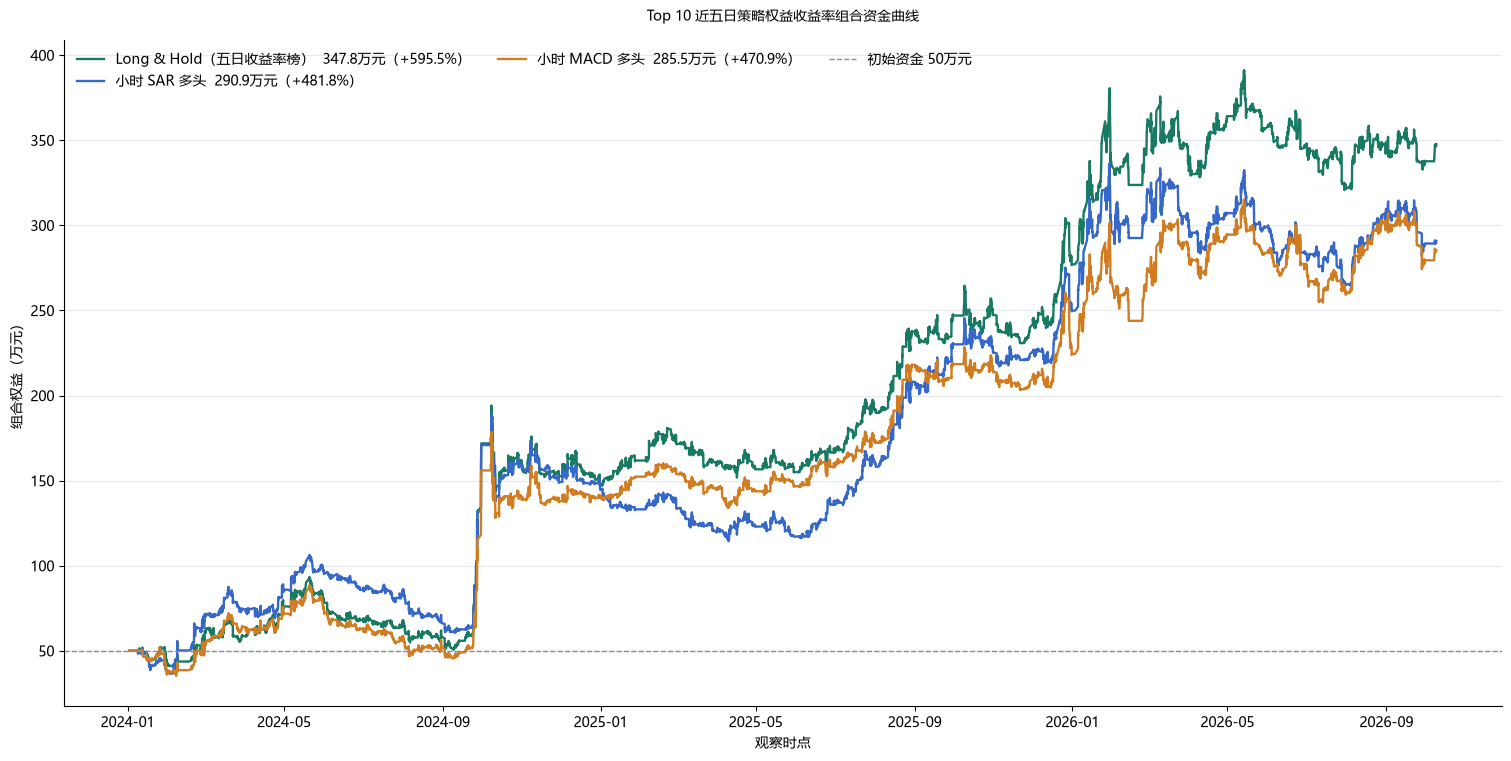

已校验：绘图 CSV 与当前 RESULTS 内存权益曲线逐行一致。


In [9]:
import csv as _csv
from datetime import datetime as _datetime
import matplotlib.dates as _mdates
import matplotlib.pyplot as _plt
from matplotlib.font_manager import FontProperties as _FontProperties
from matplotlib.ticker import FuncFormatter as _FuncFormatter

_equity_specs = [
    (strategy_id, STRATEGY_NAMES[strategy_id], STRATEGY_COLORS[strategy_id])
    for strategy_id in STRATEGY_DIRS
]
_output_dir = OUTPUT_DIR
_output_dir.mkdir(parents=True, exist_ok=True)
_font = _FontProperties(fname=r"C:\Windows\Fonts\msyh.ttc")
_fig, _ax = _plt.subplots(figsize=(15, 7.5), constrained_layout=True)
for _strategy_id, _label, _color in _equity_specs:
    _csv_path = _output_dir / f"equity_curve_{_strategy_id}.csv"
    if not _csv_path.exists():
        raise FileNotFoundError(f"请先运行回测导出单元，缺少文件：{_csv_path}")
    with _csv_path.open("r", encoding="utf-8-sig", newline="") as _file:
        _rows = list(_csv.DictReader(_file))
    if not _rows:
        raise ValueError(f"权益曲线文件为空：{_csv_path}")

    # 防止误读上一轮回测遗留的 CSV：绘图前逐行核对当前 RESULTS。
    _memory_rows = RESULTS[_strategy_id]["equity_curve"]
    if len(_memory_rows) != len(_rows):
        raise RuntimeError(
            f"{_strategy_id} 的内存权益曲线有 {len(_memory_rows)} 行，但 CSV 有 {len(_rows)} 行。"
            f"请先重新运行回测，再运行 CSV 导出单元；CSV 路径：{_csv_path}"
        )
    _max_equity_diff = 0.0
    for _row_index, (_memory_row, _csv_row) in enumerate(zip(_memory_rows, _rows)):
        _memory_time = _memory_row["timestamp"]
        if isinstance(_memory_time, str):
            _memory_time = _datetime.fromisoformat(_memory_time)
        _csv_time = _datetime.fromisoformat(_csv_row["timestamp"])
        if _memory_time != _csv_time:
            raise RuntimeError(
                f"{_strategy_id} 第 {_row_index} 行时间戳不一致：内存 {_memory_time}，CSV {_csv_time}。"
                f"请重新运行 CSV 导出单元；CSV 路径：{_csv_path}"
            )
        _max_equity_diff = max(
            _max_equity_diff,
            abs(float(_memory_row["equity"]) - float(_csv_row["equity"])),
        )
    if _max_equity_diff > 1e-6:
        raise RuntimeError(
            f"{_strategy_id} 内存权益与 CSV 最大差值为 {_max_equity_diff:,.6f} 元。"
            f"这通常表示 CSV 是旧结果或读取了不同目录。请重新运行 CSV 导出单元；CSV 路径：{_csv_path}"
        )

    _times = [_datetime.fromisoformat(_row["timestamp"]) for _row in _rows]
    _equity = [float(_row["equity"]) for _row in _rows]
    _return = (_equity[-1] / INITIAL_CAPITAL - 1) * 100
    _ax.plot(_times, _equity, color=_color, linewidth=1.7,
             label=f"{_label}  {_equity[-1] / 10000:,.1f}万元（{_return:+.1f}%）")

_ax.axhline(INITIAL_CAPITAL, color="#858c98", linewidth=1, linestyle="--", label=f"初始资金 {INITIAL_CAPITAL / 10000:,.0f}万元")
_ax.set_title(f"Top {TOP_K} 近五日策略权益收益率组合资金曲线", fontsize=16, pad=14, fontproperties=_font)
_ax.set_xlabel("观察时点", fontproperties=_font)
_ax.set_ylabel("组合权益（万元）", fontproperties=_font)
_ax.yaxis.set_major_formatter(_FuncFormatter(lambda _value, _position: f"{_value / 10000:,.0f}"))
_ax.xaxis.set_major_locator(_mdates.AutoDateLocator(minticks=6, maxticks=10))
_ax.xaxis.set_major_formatter(_mdates.DateFormatter("%Y-%m"))
_ax.grid(axis="y", color="#e5e9ef", linewidth=0.8)
_ax.spines[["top", "right"]].set_visible(False)
_ax.legend(loc="best", frameon=False, ncol=min(3, len(_equity_specs)), prop=_font)
for _tick_label in (*_ax.get_xticklabels(), *_ax.get_yticklabels()):
    _tick_label.set_fontproperties(_font)
_fig.savefig(_output_dir / "top10_portfolio_equity_curve.png", dpi=180, bbox_inches="tight")
_plt.show()
print("已校验：绘图 CSV 与当前 RESULTS 内存权益曲线逐行一致。")
